# EDA of Novels and NYT bestsellers

This notebook is a combination of section A and B from our 02 and 03 lessons. It is designed to be a self-contained example of exploratory data analysis (EDA) on two datasets: the top 500 novels and the NYT hardcover fiction bestsellers.

We will inspect metadata, visualize missing information, combine two datasets, and explore title language with spaCy. Comments explain what each code cell does; the code remains runnable.

**Setup:** use a Python environment with `pandas`, `matplotlib`, `altair`, `spacy`, and `tqdm`, plus the spaCy English model `en_core_web_sm`. If needed, run `%pip install pandas matplotlib altair spacy tqdm` and `!python -m spacy download en_core_web_sm` in separate notebook cells, then restart the kernel. Data-loading cells require internet access.

**Sources:** [Top 500 novels metadata](https://github.com/melaniewalsh/responsible-datasets-in-context/tree/main/datasets/top-500-novels) and [Post45 NYT hardcover fiction bestsellers](https://github.com/Post45-Data-Collective/data/tree/main/nyt_hardcover_fiction_bestsellers). These are different selections of books; overlap describes these datasets, not all books or readers.


In [1]:
# Import our libraries
import pandas as pd
import altair as alt
from tqdm import tqdm
import spacy

## 1. Inspect the novels metadata
Look at the column types, missing values, and distributions before interpreting patterns.


In [2]:
# Read the tab-separated metadata; each row represents a novel. We add encoding="utf-8" to avoid errors with special characters in the text.
novels_df = pd.read_csv("https://raw.githubusercontent.com/melaniewalsh/responsible-datasets-in-context/refs/heads/main/datasets/top-500-novels/top-500-novels-metadata_2025-01-11.tsv", sep="\t", encoding="utf-8")


In [3]:
# Print the type of the DataFrame to confirm it was read correctly
print(f"Type of novels_df: {type(novels_df)}")

Type of novels_df: <class 'pandas.DataFrame'>


In [4]:
# Preview five rows without displaying the whole table.
novels_df.head()


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url
0,1,Don Quixote,Miguel de Cervantes,1605,Spanish,action,1547,1616,male,spa,...,"269,435","12,053",318,211,1.810748e+09,17220427,https://www.goodreads.com/book/show/3836.Don_Q...,https://en.wikipedia.org/wiki/Don_Quixote,https://www.gutenberg.org/cache/epub/996/pg996...,https://www.gutenberg.org/cache/epub/2000/pg20...
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,...,"561,016","15,380",172,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN
2,3,The Adventures of Huckleberry Finn,Mark Twain,1884,English,action,1835,1910,male,eng,...,"1,262,480","19,440",373,68,3.373178e+09,50566653,https://www.goodreads.com/book/show/2956.The_A...,https://en.wikipedia.org/wiki/Adventures_of_Hu...,https://www.gutenberg.org/cache/epub/76/pg76.txt,NaN
3,4,The Adventures of Tom Sawyer,Mark Twain,1876,English,action,1835,1910,male,eng,...,"931,898","13,603",301,88,3.373178e+09,50566653,https://www.goodreads.com/book/show/24583.The_...,https://en.wikipedia.org/wiki/The_Adventures_o...,https://www.gutenberg.org/cache/epub/74/pg74.txt,NaN
4,5,Treasure Island,Robert Louis Stevenson,1883,English,action,1850,1894,male,eng,...,"486,155","16,307",368,145,3.434000e+03,95207986,https://www.goodreads.com/book/show/295.Treasu...,https://en.wikipedia.org/wiki/Treasure_Island,https://www.gutenberg.org/cache/epub/120/pg120...,NaN


In [5]:
# Inspect the inferred data type of each column.
novels_df.dtypes


top_500_rank                  int64
title                           str
author                          str
pub_year                      int64
orig_lang                       str
genre                           str
author_birth                    str
author_death                    str
author_gender                   str
author_primary_lang             str
author_nationality              str
author_field_of_activity        str
author_occupation               str
oclc_holdings               float64
oclc_eholdings              float64
oclc_total_editions         float64
oclc_holdings_rank          float64
oclc_editions_rank          float64
gr_avg_rating               float64
gr_num_ratings                  str
gr_num_reviews                  str
gr_avg_rating_rank            int64
gr_num_ratings_rank           int64
oclc_owi                    float64
author_viaf                  object
gr_url                          str
wiki_url                        str
pg_eng_url                  

In [6]:
# Count nonmissing values and inspect memory use.
novels_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   top_500_rank              500 non-null    int64  
 1   title                     500 non-null    str    
 2   author                    500 non-null    str    
 3   pub_year                  500 non-null    int64  
 4   orig_lang                 500 non-null    str    
 5   genre                     500 non-null    str    
 6   author_birth              499 non-null    str    
 7   author_death              496 non-null    str    
 8   author_gender             500 non-null    str    
 9   author_primary_lang       500 non-null    str    
 10  author_nationality        500 non-null    str    
 11  author_field_of_activity  329 non-null    str    
 12  author_occupation         459 non-null    str    
 13  oclc_holdings             495 non-null    float64
 14  oclc_eholdings       

In [7]:
# Summarize numeric columns, including their ranges.
novels_df.describe()


,top_500_rank,pub_year,oclc_holdings,oclc_eholdings,oclc_total_editions,oclc_holdings_rank,oclc_editions_rank,gr_avg_rating,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi
count,500.000000,500.000000,495.000000,495.000000,495.000000,495.000000,495.000000,500.000000,500.000000,500.000000,4.950000e+02
mean,250.500000,1932.132000,10401.438384,2218.593939,896.642424,248.000000,248.000000,3.971440,250.500000,250.500000,1.602208e+09
std,144.481833,84.306546,5694.509003,3084.595715,1019.015572,143.038456,143.038456,0.227688,144.481833,144.481833,2.675299e+09
min,1.000000,1021.000000,996.000000,25.000000,21.000000,1.000000,1.000000,3.290000,1.000000,1.000000,1.040000e+03
25%,125.750000,1900.000000,6800.000000,352.000000,241.000000,124.500000,124.500000,3.830000,125.750000,125.750000,3.972875e+05
50%,250.500000,1948.000000,8318.000000,558.000000,485.000000,248.000000,248.000000,3.980000,250.500000,250.500000,1.675603e+07
75%,375.250000,1989.000000,12184.000000,3223.000000,1207.500000,371.500000,371.500000,4.120000,375.250000,375.250000,2.830459e+09
max,500.000000,2015.000000,37702.000000,15545.000000,9017.000000,495.000000,495.000000,4.620000,500.000000,500.000000,1.239276e+10


In [8]:
# Summarize all columns, including text categories.
novels_df.describe(include="all")


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url
count,500.000000,500,500,500.000000,500,500,499,496,500,500,...,500,500,500.000000,500.000000,4.950000e+02,500.0,480,500,500,64
unique,NaN,500,279,NaN,12,14,152,134,2,11,...,500,497,NaN,NaN,NaN,279.0,479,499,182,32
top,NaN,Don Quixote,John Grisham,NaN,English,na,1955,ALIVE,male,eng,...,"269,435","4,209",NaN,NaN,NaN,7449742.0,https://www.goodreads.com/book/show/11991.The_...,https://en.wikipedia.org/wiki/In_Search_of_Los...,NA_not-pub-domain,unavailable
freq,NaN,1,19,NaN,430,221,21,144,355,427,...,1,2,NaN,NaN,NaN,19.0,2,2,310,32
mean,250.500000,NaN,NaN,1932.132000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,250.500000,250.500000,1.602208e+09,NaN,NaN,NaN,NaN,NaN
std,144.481833,NaN,NaN,84.306546,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,144.481833,144.481833,2.675299e+09,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,1021.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.000000,1.000000,1.040000e+03,NaN,NaN,NaN,NaN,NaN
25%,125.750000,NaN,NaN,1900.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,125.750000,125.750000,3.972875e+05,NaN,NaN,NaN,NaN,NaN
50%,250.500000,NaN,NaN,1948.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,250.500000,250.500000,1.675603e+07,NaN,NaN,NaN,NaN,NaN
75%,375.250000,NaN,NaN,1989.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,375.250000,375.250000,2.830459e+09,NaN,NaN,NaN,NaN,NaN


In [9]:
# List the available column names.
novels_df.columns

Index(['top_500_rank', 'title', 'author', 'pub_year', 'orig_lang', 'genre',
       'author_birth', 'author_death', 'author_gender', 'author_primary_lang',
       'author_nationality', 'author_field_of_activity', 'author_occupation',
       'oclc_holdings', 'oclc_eholdings', 'oclc_total_editions',
       'oclc_holdings_rank', 'oclc_editions_rank', 'gr_avg_rating',
       'gr_num_ratings', 'gr_num_reviews', 'gr_avg_rating_rank',
       'gr_num_ratings_rank', 'oclc_owi', 'author_viaf', 'gr_url', 'wiki_url',
       'pg_eng_url', 'pg_orig_url'],
      dtype='str')

### Exploring and Visualizing Quirks in the Novels Dataset

In [10]:
# Filter for novels with a recorded original-language Project Gutenberg URL.
# Display the values from the first matching row so we can inspect the complete record.
novels_df[novels_df.pg_orig_url.notna()][0:1].values

array([[1, 'Don Quixote', 'Miguel de Cervantes', 1605, 'Spanish',
        'action', '1547', '1616', 'male', 'spa', 'ES', nan,
        'soldiers,poets spanish,novelists spanish,dramatists spanish,authors spanish',
        30840.0, 4992.0, 9017.0, 9.0, 1.0, 3.9, '269,435', '12,053', 318,
        211, 1810748013.0, 17220427,
        'https://www.goodreads.com/book/show/3836.Don_Quixote?from_search=true&from_srp=true&qid=Npjwg6DCCM&rank=1',
        'https://en.wikipedia.org/wiki/Don_Quixote',
        'https://www.gutenberg.org/cache/epub/996/pg996.txt',
        'https://www.gutenberg.org/cache/epub/2000/pg2000.txt']],
      dtype=object)

In [11]:
# Inspect the literal genre label "na"; a text label differs from a missing value.
novels_df[novels_df.genre == "na"]


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url
6,7,Wuthering Heights,Emily Brontë,1847,English,na,1818,1848,female,eng,...,"1,793,015","61,175",326,46,4.973900e+04,97097302,https://www.goodreads.com/book/show/6185.Wuthe...,https://en.wikipedia.org/wiki/Wuthering_Heights,https://www.gutenberg.org/cache/epub/768/pg768...,NaN
8,9,Moby Dick,Herman Melville,1851,English,na,1819,1891,male,eng,...,"557,743","22,513",481,134,2.453386e+09,27068555,https://www.goodreads.com/book/show/153747.Mob...,https://en.wikipedia.org/wiki/Moby-Dick,https://www.gutenberg.org/cache/epub/2701/pg27...,NaN
9,10,The Scarlet Letter,Nathaniel Hawthorne,1850,English,na,1804,1864,male,eng,...,"862,399","20,214",493,95,3.277000e+03,44435463,https://www.goodreads.com/book/show/12296.The_...,https://en.wikipedia.org/wiki/The_Scarlet_Letter,https://www.gutenberg.org/cache/epub/25344/pg2...,NaN
12,13,A Christmas Carol,Charles Dickens,1843,English,na,1812,1870,male,eng,...,"838,828","31,968",157,98,2.829858e+09,88666393,https://www.goodreads.com/book/show/5326.A_Chr...,https://en.wikipedia.org/wiki/A_Christmas_Carol,https://www.gutenberg.org/cache/epub/46/pg46.txt,NaN
15,16,Little Women,Louisa May Alcott,1868,English,na,1832,1888,female,eng,...,"2,218,654","50,769",100,38,1.862340e+09,29528997,https://www.goodreads.com/book/show/1934.Littl...,https://en.wikipedia.org/wiki/Little_Women,https://www.gutenberg.org/cache/epub/37106/pg3...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
486,487,The Heart of the Matter,Graham Greene,1948,English,na,1904,1991,male,eng,...,"29,061","1,720",262,442,4.861074e+07,59083415,NaN,https://en.wikipedia.org/wiki/The_Heart_of_the...,NA_not-pub-domain,NaN
489,490,A Prayer for Owen Meany,John Irving,1989,English,na,1942,ALIVE,male,eng,...,"320,040","16,305",57,188,1.429375e+08,108238891,NaN,https://en.wikipedia.org/wiki/A_Prayer_for_Owe...,NA_not-pub-domain,NaN
490,491,The God of Small Things,Arundhati Roy,1997,English,na,1961,ALIVE,female,eng,...,"296,531","19,027",283,197,5.772430e+05,76457869,NaN,https://en.wikipedia.org/wiki/The_God_of_Small...,NA_not-pub-domain,NaN
492,493,The Shack,William P. Young,2007,English,na,1955,ALIVE,male,eng,...,"648,375","35,650",386,124,1.128167e+08,78234437,NaN,https://en.wikipedia.org/wiki/The_Shack_(Young...,NA_not-pub-domain,NaN


In [12]:
# Find novels with no recorded OCLC holdings rank.
novels_df[novels_df.oclc_holdings_rank.isna()]


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url
66,67,The Red & the Black,Stendhal,1830,French,bildung,1783,1842,male,fre,...,"74,618","3,236",345,354,NaN,17823,https://www.goodreads.com/book/show/14662.The_...,https://en.wikipedia.org/wiki/The_Red_and_the_...,https://www.gutenberg.org/cache/epub/44747/pg4...,https://www.gutenberg.org/cache/epub/798/pg798...
159,160,Angels & Demons,Dan Brown,2000,English,thrillers,1964,ALIVE,male,eng,...,"3,183,837","33,786",289,20,NaN,102403515,https://www.goodreads.com/book/show/960.Angels...,https://en.wikipedia.org/wiki/Angels_%26_Demons,NA_not-pub-domain,NaN
403,404,The Rise of Silas Lapham,William Dean Howells,1885,English,na,1837,1920,male,eng,...,"4,090",281,495,494,NaN,95191935,https://www.goodreads.com/book/show/381362.The...,https://en.wikipedia.org/wiki/The_Rise_of_Sila...,https://www.gutenberg.org/cache/epub/154/pg154...,NaN
412,413,The Princess of Cleves,Madame de (Marie-Madeleine Pioche de La Vergne...,1678,French,na,1634,1693,female,fre,...,"16,080",932,496,469,NaN,95237212,https://www.goodreads.com/book/show/1048601.Th...,https://en.wikipedia.org/wiki/La_Princesse_de_...,https://www.gutenberg.org/cache/epub/467/pg467...,https://www.gutenberg.org/cache/epub/18797/pg1...
477,478,The Remains of the Day,Kazuo Ishiguro,1989,English,history,1954,ALIVE,male,eng,...,"300,925","23,933",115,196,NaN,108702574,https://www.goodreads.com/book/show/28921.The_...,https://en.wikipedia.org/wiki/The_Remains_of_t...,NA_not-pub-domain,NaN


In [13]:
# Count each recorded death year or status; missing values are excluded by default.
novels_df.author_death.value_counts()
# novels_df.groupby("author_death").size()

author_death
ALIVE    144
1870      18
1963      10
1968       9
1910       8
        ... 
2000       1
2006       1
1926       1
1974       1
1983       1
Name: count, Length: 134, dtype: int64

<Axes: xlabel='author_birth'>

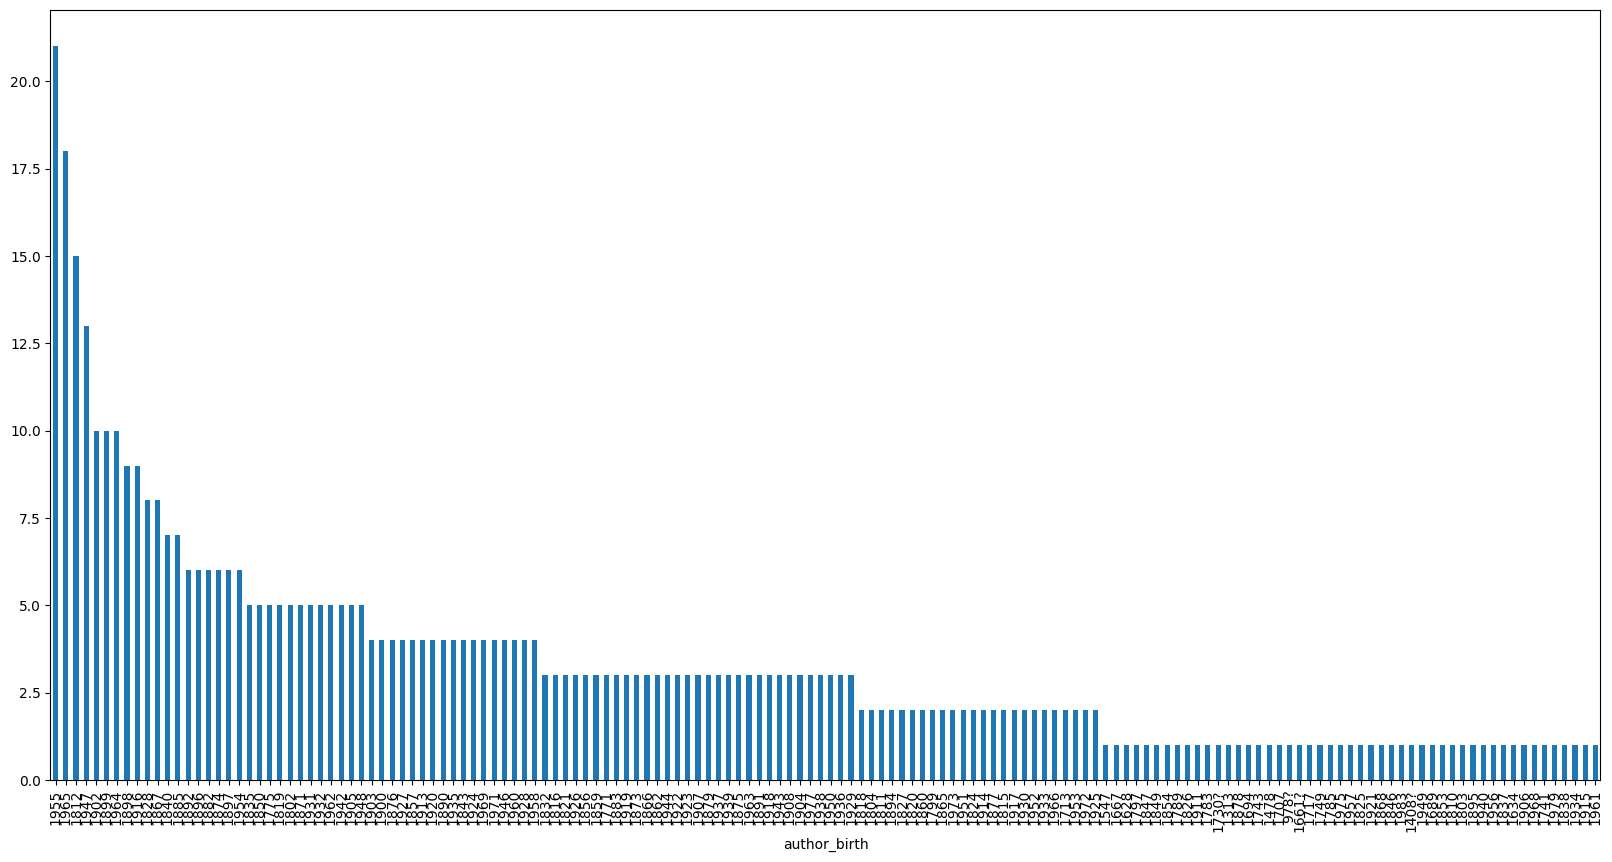

In [14]:
# Count novels by author birth year, then use Pandas' Matplotlib-backed plotting method.
author_birth_counts = novels_df.author_birth.value_counts()
author_birth_counts.plot(kind="bar", figsize=(20,10))


<Axes: xlabel='genre'>

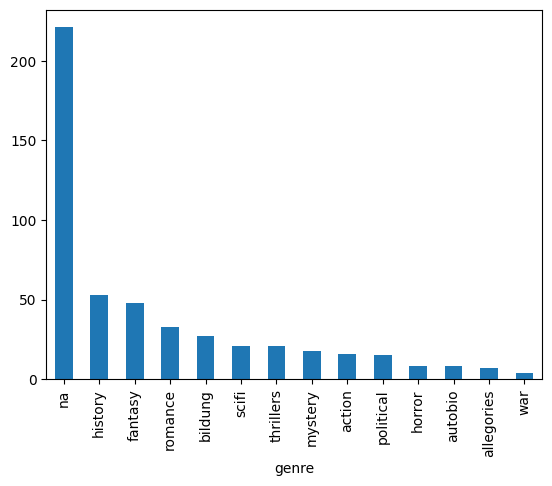

In [15]:
# Count novels by genre and display the counts as a bar chart.
novels_df.genre.value_counts().plot(kind="bar")

In [16]:
# Inspect birth years where an author activity is recorded.
novels_df[novels_df.author_field_of_activity.notna()][['author_birth', 'author_field_of_activity']]


,author_birth,author_field_of_activity
1,1832,"writing,teaching,photography,mathematics"
2,1835,"wit and humor,literature,humor"
3,1835,"wit and humor,literature,humor"
5,1775,"fiction,novels"
6,1818,"novels,fiction"
...,...,...
494,1964,"teaching,authorship"
495,1907,science fiction
496,1965,"novels,fiction"
498,1969,"fiction,drama,motion picture authorship,editing"


In [17]:
# Create a Boolean column recording whether activity metadata is present.
novels_df['has_field_of_activity'] = (
    novels_df['author_field_of_activity'].notna()
)
novels_df['has_field_of_activity'].value_counts()


has_field_of_activity
True     329
False    171
Name: count, dtype: int64

<Axes: xlabel='pub_year'>

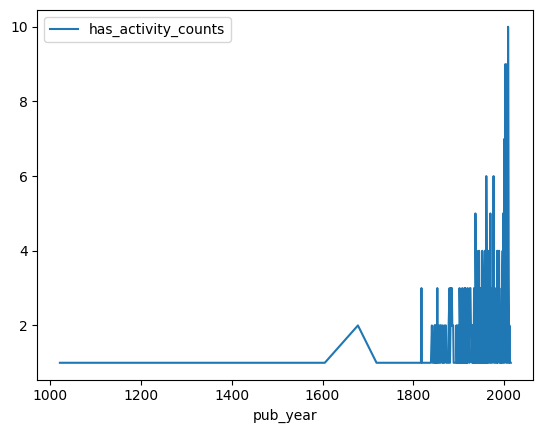

In [18]:
# Count novels by publication year and whether activity metadata is present.
activity_by_year = novels_df.groupby(['pub_year', 'has_field_of_activity']).size().reset_index()
activity_by_year = activity_by_year.rename(columns={0: 'has_activity_counts'})
# Plot the counts to explore how metadata coverage varies over time.
activity_by_year.plot(x='pub_year', y='has_activity_counts')


## 2. Visualize metadata coverage
Altair uses `N` for categories, `Q` for quantities, and `T` for dates. Missing metadata may reflect documentation practices rather than an author’s actual activities.


In [19]:
# Use Altair's sample cars data to review encodings, color, and tooltips.
from altair.datasets import data

source = data.cars()

alt.Chart(source).mark_circle(size=60).encode(
    x='Horsepower',
    y='Miles_per_Gallon',
    color='Origin',
    tooltip=['Name', 'Origin', 'Horsepower', 'Miles_per_Gallon']
)

alt.Chart(...)

In [20]:
# Compare birth-year counts and whether activity metadata is present.
alt.Chart(novels_df).mark_bar().encode(
	y="author_birth",
	x="count()",
	color="has_field_of_activity:N"
)


alt.Chart(...)

In [21]:
# Inspect the source rows behind one birth-year category.
novels_df[novels_df.author_birth == "1811"]


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url,has_field_of_activity
20,21,Uncle Tom's Cabin,Harriet Beecher Stowe,1852,English,political,1811,1896,female,eng,...,"9,800",319,230,8.104000e+03,32003151,https://www.goodreads.com/book/show/46787.Uncl...,https://en.wikipedia.org/wiki/Uncle_Tom%27s_Cabin,https://www.gutenberg.org/cache/epub/203/pg203...,NaN,True
74,75,Vanity Fair,William Makepeace Thackeray,1848,English,na,1811,1863,male,eng,...,"4,451",393,288,3.372562e+09,95208604,https://www.goodreads.com/book/show/5797.Vanit...,https://en.wikipedia.org/wiki/Vanity_Fair_(novel),https://www.gutenberg.org/cache/epub/599/pg599...,NaN,False


In [22]:
# Compare genre counts by metadata availability.
alt.Chart(novels_df).mark_bar().encode(
	x="genre",
	y="count()",
	color="has_field_of_activity:N"
)


alt.Chart(...)

In [23]:
# Compare recorded gender categories by metadata availability.
alt.Chart(novels_df).mark_bar().encode(
	x="author_gender",
	y="count()",
	color="has_field_of_activity:N"
)


alt.Chart(...)

In [24]:
# Plot publication-year counts before converting the year column to dates.
alt.Chart(novels_df).mark_bar().encode(
	x="pub_year",
	y="count():Q",
	color="has_field_of_activity:N"
)

alt.Chart(...)

In [25]:
# Now when we specify the data type of the x-axis as temporal, Altair will treat the publication year as a date BUT it is still not displaying correctly on the chart because have not turned pub_year into an actual datetime data type.
alt.Chart(novels_df).mark_bar().encode(
	x="pub_year:T",
	y="count():Q",
	color="has_field_of_activity:N"
)

alt.Chart(...)

In [26]:
# Convert publication years to datetimes; invalid values become NaT.

novels_df['book_published_year'] = pd.to_datetime(novels_df.pub_year.astype(str) + "-01-01", errors="coerce")
# Plot the converted date field and color by metadata availability.
alt.Chart(novels_df).mark_bar().encode(
	x="book_published_year:T",
	y="count():Q",
	color="has_field_of_activity:N"
)

alt.Chart(...)

In [27]:
# Inspect frequent activity labels; a cell can contain several activities.
novels_df['author_field_of_activity'].value_counts().head(20)


author_field_of_activity
english literature                                                                                                                                                                                                              28
childrens literature                                                                                                                                                                                                            21
motion pictures production and direction,motion picture authorship,law,fiction authorship,acting                                                                                                                                19
literature                                                                                                                                                                                                                      12
novels,fiction                                                     

In [28]:
# Compare genres using the original combined activity labels.
alt.Chart(novels_df).mark_bar().encode(
	x="genre",
	y="count()",
	color="author_field_of_activity:N"
)


alt.Chart(...)

In [29]:
# We can also compare the number of novels by author activity, with bars colored by genre.

alt.Chart(novels_df).mark_bar().encode(
	x="count()",
	y="author_field_of_activity",
	color="genre"
)

alt.Chart(...)

In [30]:
# Split comma-separated activities into lists before counting individual activities.
novels_df['individual_author_activity'] = (
    novels_df['author_field_of_activity'].str.split(',')
)

novels_df[[
    'author_field_of_activity',
    'individual_author_activity'
]].head(10)


,author_field_of_activity,individual_author_activity
0,NaN,NaN
1,"writing,teaching,photography,mathematics","[writing, teaching, photography, mathematics]"
2,"wit and humor,literature,humor","[wit and humor, literature, humor]"
3,"wit and humor,literature,humor","[wit and humor, literature, humor]"
4,NaN,NaN
5,"fiction,novels","[fiction, novels]"
6,"novels,fiction","[novels, fiction]"
7,"poetry,novels","[poetry, novels]"
8,"short stories,sea fiction,poetry,novels","[short stories, sea fiction, poetry, novels]"
9,NaN,NaN


In [31]:
# Put each activity on its own row; a novel may now appear more than once.
exploded_novels_df = novels_df.explode('individual_author_activity').copy()
print(f"Rows before exploding: {len(novels_df)}")
print(f"Rows after exploding: {len(exploded_novels_df)}")


Rows before exploding: 500
Rows after exploding: 1143


In [32]:
# Preview the exploded rows; they no longer correspond one-to-one with books.
exploded_novels_df.head()


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url,has_field_of_activity,book_published_year,individual_author_activity
0,1,Don Quixote,Miguel de Cervantes,1605,Spanish,action,1547,1616,male,spa,...,211,1.810748e+09,17220427,https://www.goodreads.com/book/show/3836.Don_Q...,https://en.wikipedia.org/wiki/Don_Quixote,https://www.gutenberg.org/cache/epub/996/pg996...,https://www.gutenberg.org/cache/epub/2000/pg20...,False,1605-01-01,NaN
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,...,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN,True,1865-01-01,writing
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,...,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN,True,1865-01-01,teaching
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,...,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN,True,1865-01-01,photography
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,...,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN,True,1865-01-01,mathematics


In [33]:
# Select rows with recorded activities and a genre other than the text label "na".
activity_rows = exploded_novels_df[
    (exploded_novels_df.individual_author_activity.notna())
    & (exploded_novels_df.genre != "na")
]
# Each tile counts book-activity rows, separated by recorded gender.
alt.Chart(activity_rows).mark_rect().encode(
    x='genre:N',
    y='individual_author_activity:N',
    color='count():Q',
    column='author_gender:O',
    tooltip=['genre:N', 'individual_author_activity:N', 'count():Q']
)


alt.Chart(...)

## 3. Combine the datasets and label their origins

To augment the OCLC data, we will combine it with the NYT Bestsellers dataset. First, inspect the NYT data so that we understand what its rows and columns represent before choosing how to merge it.


In [34]:
# Load the weekly NYT bestseller-list entries.
nyt_bestsellers_df = pd.read_csv("https://raw.githubusercontent.com/Post45-Data-Collective/data/refs/heads/main/nyt_hardcover_fiction_bestsellers/nyt_hardcover_fiction_bestsellers-lists.csv", encoding="utf-8")


In [35]:
# Preview weekly entries; a title may appear on more than one list.
nyt_bestsellers_df.head()


,Unnamed: 0,author,author_authorized_heading,author_lccn,author_viaf,author_wikidata,oclc_eholdings,oclc_holdings,oclc_isbn,oclc_owi,rank,title,title_id,week,year
0,0,Warwick Deeping,"Deeping, Warwick",n82131987,76774191,Q2550081,10.0,190.0,NaN,23650160.0,1,THE TEN COMMANDMENTS,6477,1931-10-12,1931
1,1,Mazo de la Roche,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,FINCHE'S FORTUNE,1808,1931-10-12,1931
2,2,Pearl S. Buck,"Buck, Pearl S. (1892-1973)",n79026662,91868694,Q80900,941.0,11823.0,9780743272933,267164.0,3,THE GOOD EARTH,5304,1931-10-12,1931
3,3,Willa Cather,"Cather, Willa, 1873-1947",n80015717,2480701,Q229480,96.0,2155.0,0679764046,1288595.0,4,SHADOWS ON THE ROCK,4038,1931-10-12,1931
4,4,Rafael Sabatini,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,SCARMOUCHE THE KING MAKER,3946,1931-10-12,1931


In [36]:
# Use info to explore the data types and nonmissing values in the NYT bestsellers DataFrame.

nyt_bestsellers_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60386 entries, 0 to 60385
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 60386 non-null  int64  
 1   author                     60376 non-null  str    
 2   author_authorized_heading  55717 non-null  str    
 3   author_lccn                55622 non-null  str    
 4   author_viaf                55717 non-null  object 
 5   author_wikidata            54485 non-null  str    
 6   oclc_eholdings             56567 non-null  float64
 7   oclc_holdings              56567 non-null  float64
 8   oclc_isbn                  33723 non-null  str    
 9   oclc_owi                   56567 non-null  float64
 10  rank                       60386 non-null  int64  
 11  title                      60386 non-null  str    
 12  title_id                   60386 non-null  int64  
 13  week                       60386 non-null  str    
 14  y

In [37]:
# Explore the distribution of data even for non-numeric columns
nyt_bestsellers_df.describe(include="all")


,Unnamed: 0,author,author_authorized_heading,author_lccn,author_viaf,author_wikidata,oclc_eholdings,oclc_holdings,oclc_isbn,oclc_owi,rank,title,title_id,week,year
count,60386.000000,60376,55717,55622,55717.0,54485,56567.000000,56567.000000,33723,5.656700e+04,60386.000000,60386,60386.000000,60386,60386.000000
unique,NaN,2210,2278,1802,1814.0,1660,NaN,NaN,4251,NaN,NaN,7172,NaN,4621,NaN
top,NaN,Danielle Steel,"Steel, Danielle",n80061569,100238676.0,Q72653,NaN,NaN,0679805273,NaN,NaN,"OH, THE PLACES YOU'LL GO!",NaN,1987-08-16,NaN
freq,NaN,957,953,953,953.0,953,NaN,NaN,178,NaN,NaN,178,NaN,18,NaN
mean,30192.500000,NaN,NaN,NaN,NaN,NaN,177.706224,3177.302438,NaN,1.190394e+09,7.578329,NaN,3810.020154,NaN,1980.291375
std,17432.081015,NaN,NaN,NaN,NaN,NaN,173.804251,2503.022383,NaN,2.310438e+09,4.401472,NaN,2118.650219,NaN,24.440366
min,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,NaN,3.115000e+03,1.000000,NaN,0.000000,NaN,1931.000000
25%,15096.250000,NaN,NaN,NaN,NaN,NaN,57.000000,1557.000000,NaN,9.252610e+05,4.000000,NaN,2012.000000,NaN,1958.000000
50%,30192.500000,NaN,NaN,NaN,NaN,NaN,134.000000,2810.000000,NaN,5.223647e+07,7.000000,NaN,3931.500000,NaN,1982.000000
75%,45288.750000,NaN,NaN,NaN,NaN,NaN,241.000000,4151.000000,NaN,1.166148e+09,11.000000,NaN,5599.000000,NaN,2001.000000


To merge these datasets, we first need to determine which columns can identify the same book in both sources.

We match on author and a lowercased title. This is an approximate match: spelling differences, punctuation, and author-name variations can keep the same book from matching. 

In [39]:
# Lowercase each dataset's titles for matching, keeping the original title columns.
novels_df['title_key'] = novels_df['title'].str.lower()
nyt_bestsellers_df['title_key'] = nyt_bestsellers_df['title'].str.lower()

# Find the shared columns
shared_columns = list(set(nyt_bestsellers_df.columns).intersection(set(novels_df.columns)))
print(f"Shared columns: {shared_columns}")
shared_columns.remove("title") # We removed the title column from the shared columns, but we want to keep it for merging but use the suffixes to distinguish the two title columns.
# An outer merge keeps books found in either dataset. The indicator column records which dataset each row came from.
merged_df = novels_df.merge(
    nyt_bestsellers_df, how='outer', on=shared_columns,
    suffixes=('_oclc', '_nyt'), indicator=True
)
merged_df.head()



Shared columns: ['oclc_holdings', 'author', 'oclc_eholdings', 'title_key', 'author_viaf', 'title', 'oclc_owi']


,top_500_rank,title_oclc,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,author_authorized_heading,author_lccn,author_wikidata,oclc_isbn,rank,title_nyt,title_id,week,year,_merge
0,NaN,NaN,James Patterson and Howard Roughan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"Patterson, James; &amp; Roughan, Howard, 1947-",n00039004,Q5920764,0316036234,2.0,DON'T BLINK,1494.0,2010-10-17,2010.0,right_only
1,NaN,NaN,James Patterson and Howard Roughan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"Patterson, James; &amp; Roughan, Howard, 1947-",n00039004,Q5920764,0316036234,7.0,DON'T BLINK,1494.0,2010-10-24,2010.0,right_only
2,NaN,NaN,James Patterson and Howard Roughan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"Patterson, James; &amp; Roughan, Howard, 1947-",n00039004,Q5920764,0316036234,9.0,DON'T BLINK,1494.0,2010-10-31,2010.0,right_only
3,NaN,NaN,James Patterson and Howard Roughan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"Patterson, James; &amp; Roughan, Howard, 1947-",n00039004,Q5920764,0316036234,11.0,DON'T BLINK,1494.0,2010-11-07,2010.0,right_only
4,NaN,NaN,James Patterson and Howard Roughan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,"Patterson, James; &amp; Roughan, Howard, 1947-",n00039004,Q5920764,0316036234,13.0,DON'T BLINK,1494.0,2010-11-14,2010.0,right_only


In [40]:
# Replace merge-indicator values with readable source-group labels.

merged_df['dataset_group'] = merged_df['_merge'].map({
	'right_only': 'NYT only',
	'both': 'OCLC and NYT',
	'left_only': 'OCLC only'
})

In [41]:
# Measure each matching title in characters and whitespace-separated words.
merged_df['title_len'] = merged_df.title_key.str.len()
merged_df['title_word_count'] = merged_df.title_key.str.split(' ').str.len()

In [42]:
# Prefer the OCLC publication year, fill gaps with the NYT year, and convert to datetime.
merged_df['book_publication_year'] = merged_df.pub_year
merged_df['book_publication_year'] = merged_df.book_publication_year.fillna(merged_df['year'])
merged_df['book_publication_year'] = pd.to_datetime(merged_df.book_publication_year.astype(int).astype(str) + "-01-01", errors="coerce")

## 4. Explore title language

Questions: Do title lengths or grammatical patterns differ between the source groups? How do those patterns change over list dates? What might the selection and matching methods explain?

spaCy predicts grammatical labels and named entities, so inspect its predictions before interpreting the resulting counts. We use a function to process each lowercase title. Lowercasing can affect proper-noun and entity predictions, and repeated authors can contribute several books to the merged data.


In [43]:
# Load the English model once; it must be installed in the notebook's environment.
import spacy
nlp = spacy.load('en_core_web_sm')
# Inspect tokens and named entities in an example title.
example_title = nlp("Harry Potter and the Philosopher's Stone")
for token in example_title:
    print(token.text, token.pos_)
for entity in example_title.ents:
    print(entity.text, entity.label_)


Harry PROPN
Potter PROPN
and CCONJ
the DET
Philosopher PROPN
's PART
Stone PROPN
Harry Potter PERSON


In [ ]:
# Select longer titles found in both datasets and summarize their NYT appearances.
# Compare spaCy predictions for lowercase, title-case, and uppercase versions.
grouped_titles_df = merged_df[(merged_df.title_word_count > 3) & (merged_df.top_500_rank.notna()) & (merged_df['rank'].notna())].groupby(['title_oclc', 'title_key', 'title_nyt', 'author', 'pub_year', 'title_len', 'title_word_count']).agg(
	nyt_first_week=('week', 'min'),
	best_nyt_rank=('rank', 'min'),
	avg_best_rank=('rank', 'mean')
).reset_index()
for index, row in grouped_titles_df.iterrows():
	print(index, row['title_key'])
	lowercase_title_doc = nlp(row['title_key'])
	
	print("Lowercase examples", index, row['title_key'])
	for word in lowercase_title_doc:
		print(word.text, word.pos_)

	for entity in lowercase_title_doc.ents:
		print(entity.text, entity.label_)
	capitalized_title_doc = nlp(row['title_oclc'])
	print("Capitalized examples", index, row['title_oclc'])
	for word in capitalized_title_doc:
			print(word.text, word.pos_)
	
	for entity in capitalized_title_doc.ents:
		print(entity.text, entity.label_)
	uppercase_title_doc = nlp(row['title_nyt'])
	print("Uppercase examples", index, row['title_nyt'])
	for word in uppercase_title_doc:
			print(word.text, word.pos_)
	
	for entity in uppercase_title_doc.ents:
		print(entity.text, entity.label_)
	print("******")

0 a prayer for owen meany
Lowercase examples 0 a prayer for owen meany
a DET
prayer NOUN
for ADP
owen PROPN
meany PROPN
Capitalized examples 0 A Prayer for Owen Meany
A DET
Prayer PROPN
for ADP
Owen PROPN
Meany PROPN
Uppercase examples 0 A PRAYER FOR OWEN MEANY
A DET
PRAYER NOUN
FOR ADP
OWEN ADJ
MEANY PROPN
******
1 a thousand splendid suns
Lowercase examples 1 a thousand splendid suns
a DET
thousand NUM
splendid ADJ
suns NOUN
thousand CARDINAL
Capitalized examples 1 A Thousand Splendid Suns
A DET
Thousand PROPN
Splendid PROPN
Suns PROPN
Uppercase examples 1 A THOUSAND SPLENDID SUNS
A DET
THOUSAND NUM
SPLENDID NOUN
SUNS ADV
SUNS ORG
******
2 a tree grows in brooklyn
Lowercase examples 2 a tree grows in brooklyn
a DET
tree NOUN
grows VERB
in ADP
brooklyn PROPN
brooklyn GPE
Capitalized examples 2 A Tree Grows in Brooklyn
A DET
Tree NOUN
Grows VERB
in ADP
Brooklyn PROPN
Brooklyn GPE
Uppercase examples 2 A TREE GROWS IN BROOKLYN
A DET
TREE NOUN
GROWS VERB
IN ADP
BROOKLYN PROPN
BROOKLYN GPE

### Approach 1: loop through rows with `iterrows()`
Now that we have determined that we'll use lowercased titles for matching, we can explore the title language with spaCy. We will use a `for` loop to iterate through each row of the merged DataFrame, process the title with spaCy, and collect the results in a list of dictionaries. Each dictionary will contain the title, its tokens, and its named entities. Finally, we will create a new DataFrame from this list of dictionaries.

In [45]:
# Start an empty list to hold one dictionary of measurements per row.
title_analysis_rows = []
# iterrows gives us the row index and its values for each merged entry.
for index, row in merged_df.iterrows():
    # Replace missing titles with empty text so spaCy can process them.
    title = row['title_key']
    if pd.isna(row['title_key']):
        title = ''
    # Assign POS tags and identify named entities in this title.
    title_doc = nlp(title)

    # Reset the counters for each new row.
    noun_count = 0
    proper_noun_count = 0
    verb_count = 0
    adjective_count = 0
    determiner_count = 0
    # Count words with each grammatical tag.
    for word in title_doc:
        if word.pos_ == 'NOUN':
            noun_count = noun_count + 1
        if word.pos_ == 'PROPN':
            proper_noun_count = proper_noun_count + 1
        if word.pos_ == 'VERB':
            verb_count = verb_count + 1
        if word.pos_ == 'ADJ':
            adjective_count = adjective_count + 1
        if word.pos_ == 'DET':
            determiner_count = determiner_count + 1
    # Collect entity text and labels in a list.
    entities = []
    for entity in title_doc.ents:
        entity_information = (entity.text, entity.label_)
        entities.append(entity_information)
    # Add this row’s measurements as a dictionary to our results list.
    title_analysis_rows.append({
        "title": title,
        "author": row['author'],
        "book_publication_year": row['book_publication_year'],
        "title_len": row['title_len'],
        "title_word_count": row['title_word_count'],
        'noun_count': noun_count,
        'proper_noun_count': proper_noun_count,
        'verb_count': verb_count,
        'adjective_count': adjective_count,
        'determiner_count': determiner_count,
        'entity_count': len(title_doc.ents),
        'entities': entities
    })


In [46]:
# Turn our list of dictionaries into a DataFrame and summarize its numeric columns.
title_analysis_df = pd.DataFrame(title_analysis_rows)
title_analysis_df.describe()


,book_publication_year,title_len,title_word_count,noun_count,proper_noun_count,verb_count,adjective_count,determiner_count,entity_count
count,60770,60770.000000,60770.000000,60770.000000,60770.000000,60770.000000,60770.000000,60770.000000,60770.000000
mean,1979-10-27 14:08:42.968570,16.040892,2.926312,1.108787,0.349942,0.166135,0.242784,0.541731,0.231150
min,1021-01-01 00:00:00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1958-01-01 00:00:00,11.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1982-01-01 00:00:00,15.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2001-01-01 00:00:00,20.000000,4.000000,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,2020-01-01 00:00:00,75.000000,13.000000,5.000000,6.000000,3.000000,3.000000,3.000000,3.000000
std,NaN,6.590771,1.356509,0.721908,0.691239,0.398096,0.470806,0.586377,0.442594


### Approach 2: a function with `progress_apply()`

Now put the processing steps inside a function and apply it to each row. Instead of appending dictionaries, the function returns values that become columns in `merged_df`. `progress_apply()` works like `apply()` while displaying a progress bar.

`progress_apply()` is a method from the `tqdm` library that allows you to apply a function to each row of a DataFrame while displaying a progress bar. This is useful for long-running operations, as it provides feedback on how much of the operation has been completed.


In [52]:
nyt_titles_df = nyt_bestsellers_df.groupby(['author', 'title_key']).agg(
	publication_year=('year', 'min'),
	best_nyt_rank=('rank', 'min'),
	avg_nyt_rank=('rank', 'mean'),
).reset_index()
# Find the shared columns
shared_columns = list(set(nyt_titles_df.columns).intersection(set(novels_df.columns)))
print(f"Shared columns: {shared_columns}")
# An outer merge keeps books found in either dataset. The indicator column records which dataset each row came from.
merged_df = novels_df.merge(
    nyt_titles_df, how='outer', on=shared_columns,
    suffixes=('_oclc', '_nyt'), indicator=True
)
# Replace merge-indicator values with readable source-group labels.

merged_df['dataset_group'] = merged_df['_merge'].map({
	'right_only': 'NYT only',
	'both': 'OCLC and NYT',
	'left_only': 'OCLC only'
})
# Measure each title in characters and whitespace-separated words.
merged_df['title_len'] = merged_df.title_key.str.len()
merged_df['title_word_count'] = merged_df.title_key.str.split(' ').str.len()

# Prefer the OCLC publication year, fill gaps with the NYT year, and convert to datetime.
merged_df['book_publication_year'] = merged_df.pub_year
merged_df['book_publication_year'] = merged_df.book_publication_year.fillna(merged_df['publication_year'])
merged_df['book_publication_year'] = pd.to_datetime(merged_df.book_publication_year.astype(int).astype(str) + "-01-01", errors="coerce")
merged_df.head()

Shared columns: ['title_key', 'author']


,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,...,individual_author_activity,title_key,publication_year,best_nyt_rank,avg_nyt_rank,_merge,dataset_group,title_len,title_word_count,book_publication_year
0,NaN,NaN,Sue Grafton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"""h"" is for homicide",1991.0,2.0,8.866667,right_only,NYT only,19,4,1991-01-01
1,NaN,NaN,Sue Grafton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"""i"" is for innocent",1992.0,2.0,7.000000,right_only,NYT only,19,4,1992-01-01
2,NaN,NaN,Sue Grafton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"""j"" is for judgment",1993.0,3.0,7.600000,right_only,NYT only,19,4,1993-01-01
3,NaN,NaN,Sue Grafton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"""k"" is for killer",1994.0,2.0,4.333333,right_only,NYT only,17,4,1994-01-01
4,NaN,NaN,Sue Grafton,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,"""l"" is for lawless",1995.0,1.0,5.000000,right_only,NYT only,18,4,1995-01-01


In [54]:
# Extract POS counts and named entities using the function we wrote in class.
def process_titles(row):
	# Use the lowercase title and replace a missing title with empty text.
	title = row['title_key']
	if pd.isna(title):
		title = ''
	# Ask spaCy to assign grammatical tags and identify entities.
	title_doc = nlp(title)
	
	# Start each counter at zero before examining the words.
	noun_count = 0
	proper_noun_count = 0
	verb_count = 0
	adjective_count = 0
	determiner_count = 0
	title_labels = []
	# Add one to the matching counter for each word.
	for word in title_doc:
		if word.pos_ == 'NOUN':
			noun_count = noun_count + 1
		if word.pos_ == 'PROPN':
			proper_noun_count = proper_noun_count + 1
		if word.pos_ == 'VERB':
			verb_count = verb_count + 1
		if word.pos_ == 'ADJ':
			adjective_count = adjective_count + 1
		if word.pos_ == 'DET':
			determiner_count = determiner_count + 1
		title_labels.append((word.text, word.pos_))
	# Save each entity together with its predicted label.
	entities = []
	for entity in title_doc.ents:
		entity_information = (entity.text, entity.label_)
		entities.append(entity_information)
	return title_labels, noun_count, proper_noun_count, verb_count, adjective_count, determiner_count, len(title_doc.ents), entities

# Run the function once per merged book record and expand its returned values into columns.
tqdm.pandas(desc="Processing titles through spaCy")
merged_df[['title_labels', 'noun_count', 'proper_noun_count', 'verb_count', 'adjective_count', 'determiner_count', 'entity_count', 'entities']] = merged_df.progress_apply(process_titles, axis=1, result_type="expand")


Processing titles through spaCy: 100%|██████████| 7797/7797 [00:19<00:00, 403.98it/s]


## 5. Compare and visualize the measurements

We aggregate before plotting so charts do not embed every book or weekly list entry. Group means describe the records in this merge; they are not estimates for all literature. Books matched to multiple OCLC records can contribute more than once.


In [71]:
# Select only the measurements we want to compare.
metric_columns = [
    'title_len', 'title_word_count', 'noun_count', 'proper_noun_count',
    'verb_count', 'adjective_count', 'determiner_count', 'entity_count'
]
# Melt converts one column per measurement into a measurement/value pair.
# These identifiers exist after the title-level merge; weekly rank/week columns do not.
melted_merged_df = merged_df.melt(
    id_vars=['author', 'title_key', 'dataset_group', 'book_publication_year'],
    value_vars=metric_columns,
    var_name='title_count_type', value_name='title_counts'
)
# Compute means by source group and measurement to keep the chart data small.
group_summary = (
    melted_merged_df.groupby(['dataset_group', 'title_count_type'], observed=True)
    ['title_counts'].mean().reset_index()
)
# Independent scales prevent character counts from dwarfing grammatical counts.
alt.Chart(group_summary).mark_bar().encode(
    x=alt.X('dataset_group:N', title='Dataset group'),
    y=alt.Y('title_counts:Q', title='Mean per book record'),
    color='dataset_group:N', row='title_count_type:N',
    tooltip=['dataset_group:N', 'title_count_type:N', 'title_counts:Q']
).resolve_scale(y='independent')


alt.Chart(...)

In [72]:
# Keep records with a usable publication year and extract the year from the datetime.
dated_titles = merged_df.dropna(subset=['book_publication_year']).copy()
dated_titles['publication_year'] = dated_titles['book_publication_year'].dt.year
# Calculate yearly averages before sending the data to Altair.
yearly_lengths = (
    dated_titles.groupby('publication_year')['title_word_count'].mean().reset_index()
)
alt.Chart(yearly_lengths).mark_line(point=True).encode(
    x=alt.X('publication_year:O', title='Publication year'),
    y=alt.Y('title_word_count:Q', title='Mean title word count'),
    tooltip=['publication_year:O', 'title_word_count:Q']
)


alt.Chart(...)